# WDSD: EDA orientado a instancias

**Autores:** Jose David Castillo e Ivan Berrio.

Entregable 1 de Deep Learning. Este notebook rehace el EDA de WDSD con cada tornillo como unidad de análisis. Responde al bloque G del enunciado (segmentación de imágenes) y al EDA general 2.1, ahora medidos por instancia.

Su relación con [`01_eda_wdsd.ipynb`](01_eda_wdsd.ipynb):

- **Lo que se hereda sin repetir:** inventario, huella SHA-256, casi duplicados por pHash, grupos de independencia, partición agrupada congelada, intensidad y normalización. Esos análisis no dependen de si la salida es semántica o de instancias.
- **Lo que cambia:** la verdad de referencia pasa a ser el polígono COCO de cada tornillo, la métrica primaria pasa a ser de instancia y la declaración a priori se sustituye por `results/eda/declaracion_a_priori_instancias.json`.

Como en el 01, cada análisis termina con la decisión de preprocesamiento, el impacto en la arquitectura y los riesgos. No se entrena ningún modelo.

## 0. Configuración

In [1]:
import sys, json, platform, warnings
from pathlib import Path
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from PIL import Image
from scipy import stats, ndimage as ndi
from skimage import measure
from skimage.segmentation import find_boundaries
from wdsd_e1 import eda as E, instancias as N

SEED = E.SEED
rng = np.random.default_rng(SEED)
COLOR = {'train': '#2a78d6', 'val': '#eb6834', 'test': '#1baf7a'}
SPLITS = ['train', 'val', 'test']
TINTA, GRIS, ACENTO = '#0b0b0b', '#52514e', '#2a78d6'
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ae',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': .7, 'axes.axisbelow': True,
    'text.color': TINTA, 'axes.labelcolor': GRIS, 'xtick.color': GRIS, 'ytick.color': GRIS,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 9.5, 'legend.frameon': False})
pd.set_option('display.width', 180, 'display.max_columns', 30)
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__)

Python 3.9.25 | numpy 1.25.2 | pandas 2.1.0 | matplotlib 3.7.2


## 1. Definición del problema como segmentación de instancias

**Tipo de problema:** 8, segmentación de imágenes, en su variante de instancias. El enunciado no separa semántica e instancias, así que el tipo declarado no cambia; cambian la salida, la métrica y la unidad de error.

**Formulación.** La entrada es una imagen $x \in \mathcal{X} = [0,255]^{720 \times 1280 \times 3}$. La salida es un conjunto de máscaras disjuntas, una por tornillo, $y = \{M_1, \dots, M_K\}$ con $M_k \subset \Omega = \{1..720\} \times \{1..1280\}$ y $K$ variable. Se busca $f: \mathcal{X} \to \mathcal{Y}$ que acierte cuántos tornillos hay y dónde está cada uno. La pérdida que se minimiza depende del modelo; para los modelos base del enunciado (FCN, codificador-decodificador, U-Net reducida) es una pérdida por píxel, Dice más entropía cruzada, seguida de un etiquetado de componentes conexas que convierte la máscara en instancias. La sección 6 comprueba que ese paso es válido en este dataset.

**Pregunta de investigación.** ¿Cuál de los tres modelos base de la literatura localiza mejor cada tornillo en escenas de desmontaje de RAEE con escenas nunca vistas en el entrenamiento, y qué nivel debe superar un modelo avanzado?

**Hipótesis operativa.** Las diferencias de F1 de instancia por imagen entre los modelos base son mayores que el margen $\delta$ declarado en la sección 13.

**Unidad de independencia:** el grupo de escena del notebook 01 (186 grupos). La imagen es la unidad de medida de la métrica y el grupo es la unidad de remuestreo para la inferencia.

## 2. Estructura de las anotaciones de instancia

In [2]:
df = E.inventario()
par = pd.read_csv(E.RESULTS / 'particion.csv')
dec01 = json.load(open(E.RESULTS / 'declaracion_a_priori.json', encoding='utf8'))
coco = E.carga_coco()
filas = []
for k in SPLITS:
    d = coco[k]
    a = d['annotations']
    filas.append({'split_oficial': k, 'imagenes': len(d['images']), 'instancias': len(a),
        'categorias': ', '.join(c['name'] for c in d['categories']),
        'ids_unicos': len({x['id'] for x in a}) == len(a),
        'iscrowd_1': sum(x['iscrowd'] for x in a),
        'con_2_poligonos': sum(len(x['segmentation']) > 1 for x in a),
        'imagenes_sin_instancia': len({i['id'] for i in d['images']} - {x['image_id'] for x in a})})
display(pd.DataFrame(filas).set_index('split_oficial'))
print('Huella del dataset igual a la del EDA 01:', E.huella_dataset(df) == dec01['sha256_dataset'])

ins, acu = N.tablas_instancias(df)
ins = ins.merge(par[['archivo', 'split', 'grupo', 'familia']], on='archivo', how='left')
ins['diametro'] = np.sqrt(4 * ins.area_coco / np.pi)
print('Instancias:', len(ins), '| sin partición asignada:', ins.split.isna().sum(),
      '| imágenes con instancias:', ins.archivo.nunique(), 'de', len(df))

,imagenes,instancias,categorias,ids_unicos,iscrowd_1,con_2_poligonos,imagenes_sin_instancia
split_oficial,,,,,,,
train,765,3578,Screw,True,0,2,0
val,90,402,Screw,True,0,0,0
test,90,418,Screw,True,0,0,0


Huella del dataset igual a la del EDA 01: True
Instancias: 4398 | sin partición asignada: 0 | imágenes con instancias: 945 de 945


Hay una sola categoría (`Screw`), ninguna anotación de grupo (`iscrowd = 0`) y todas las imágenes tienen al menos un tornillo. Solo 2 de 4.398 instancias están partidas en dos polígonos.

**Decisión de preprocesamiento.** Se usa una sola clase y se trata cada anotación como una instancia, uniendo los dos polígonos de las 2 instancias partidas.

**Impacto en la arquitectura.** Basta una salida binaria (tornillo o fondo) más la separación en instancias; no hace falta cabeza de clasificación multiclase.

**Riesgos.** Como no hay imágenes sin tornillos, el conjunto de prueba no mide falsos positivos en escenas vacías. Esto se declara como limitación de validez externa.

## 3. Calidad de las anotaciones de instancia

Se comprueban tres cosas: que el área declarada coincide con el polígono, que la caja coincide con el polígono y cuánto se parecen las dos versiones de la anotación (polígonos COCO y máscara PNG).

In [3]:
print('Píxeles rasterizados por centros de píxel igual a area COCO:', (ins.px == ins.area_coco).mean())
desf = pd.DataFrame({'x0': ins.x - ins.px_x0, 'y0': ins.y - ins.px_y0,
                     'x1': ins.x + ins.w - ins.px_x1, 'y1': ins.y + ins.h - ins.px_y1})
print('Desfase caja - polígono (valor más frecuente por lado):', desf.round(1).mode().iloc[0].to_dict())
raras = ins.loc[(desf.round(1) != 0.5).any(axis=1), ['archivo', 'split_oficial', 'id', 'w', 'h', 'px_x0', 'px_x1', 'px_y0', 'px_y1']]
print('Cajas que no envuelven su polígono:', len(raras)); display(raras)
print('\nIoU por instancia COCO frente a su componente PNG:')
display(ins.iou_png.describe(percentiles=[.01, .05, .5, .95]).round(3).to_frame().T)
print('Instancias que comparten componente PNG con otra:', (ins.instancias_en_componente > 1).sum(),
      '| componentes PNG sin instancia COCO:', int((acu.n_comp_png - acu.n_coco).clip(lower=0).sum()))
techo = pd.DataFrame({u: {'F1 medio por imagen': acu[f'f1_{u}'].mean(), 'imagenes con F1 < 1': (acu[f'f1_{u}'] < 1).mean(),
                          'SQ medio': acu[f'sq_{u}'].mean(), 'PQ medio': acu[f'pq_{u}'].mean()} for u in N.UMBRALES})
techo.columns = [f'IoU >= {u}' for u in N.UMBRALES]
print('\nAcuerdo entre las dos versiones de la anotación (COCO como verdad, PNG como predicción):'); display(techo.round(4))

Píxeles rasterizados por centros de píxel igual a area COCO: 1.0
Desfase caja - polígono (valor más frecuente por lado): {'x0': 0.5, 'y0': 0.5, 'x1': 0.5, 'y1': 0.5}
Cajas que no envuelven su polígono: 0


,archivo,split_oficial,id,w,h,px_x0,px_x1,px_y0,px_y1



IoU por instancia COCO frente a su componente PNG:


,count,mean,std,min,1%,5%,50%,95%,max
iou_png,4398.0,0.833,0.065,0.458,0.649,0.717,0.839,0.929,0.984


Instancias que comparten componente PNG con otra: 0 | componentes PNG sin instancia COCO: 4

Acuerdo entre las dos versiones de la anotación (COCO como verdad, PNG como predicción):


,IoU >= 0.5,IoU >= 0.75
F1 medio por imagen,0.9995,0.9063
imagenes con F1 < 1,0.0053,0.2582
SQ medio,0.8423,0.8408
PQ medio,0.8419,0.7765


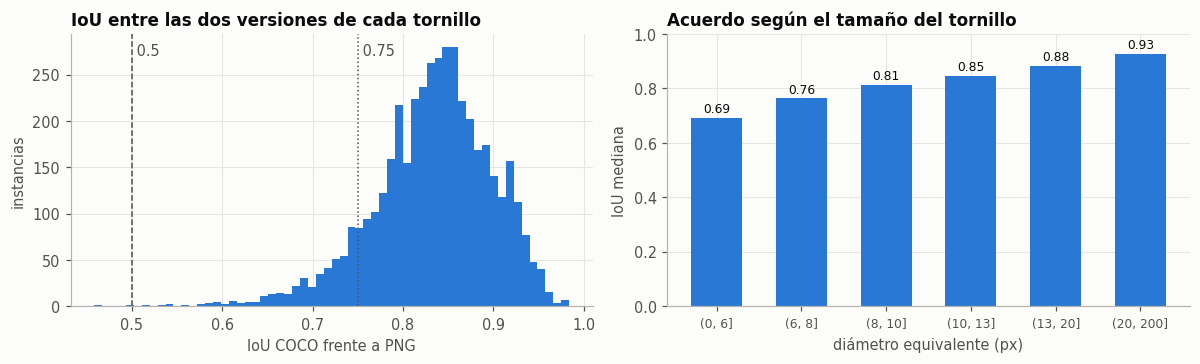

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(ins.iou_png, bins=60, color=ACENTO)
for u, ls in zip(N.UMBRALES, ['--', ':']):
    ax[0].axvline(u, color=GRIS, ls=ls, lw=1); ax[0].text(u, ax[0].get_ylim()[1] * .92, f' {u}', color=GRIS)
ax[0].set(title='IoU entre las dos versiones de cada tornillo', xlabel='IoU COCO frente a PNG', ylabel='instancias')
b = ins.assign(rango=pd.cut(ins.diametro, [0, 6, 8, 10, 13, 20, 200])).groupby('rango', observed=True).iou_png
ax[1].bar(range(len(b.median())), b.median(), color=ACENTO, width=.6)
ax[1].set_xticks(range(len(b.median()))); ax[1].set_xticklabels([str(i) for i in b.median().index], rotation=0, fontsize=8)
ax[1].set(title='Acuerdo según el tamaño del tornillo', xlabel='diámetro equivalente (px)', ylabel='IoU mediana', ylim=(0, 1))
for i, v in enumerate(b.median()): ax[1].text(i, v + .02, f'{v:.2f}', ha='center', fontsize=8)
plt.tight_layout(); plt.show()

- **Área:** rasterizando el polígono por centros de píxel, el número de píxeles coincide exactamente con `area` en todas las instancias. Rasterizar con `ImageDraw.polygon` añade el contorno y engorda cada tornillo unos 19 px, lo que en un objeto de 70 px es un sesgo del 25 %. Por eso `N.etiqueta_coco` usa centros de píxel.
- **Cajas:** la convención es la misma en todas las instancias: la caja va 0,5 px por fuera del polígono, porque los vértices están en bordes de píxel. Ninguna caja deja fuera parte de su polígono.
- **Dos versiones:** el PNG no es la rasterización del COCO: es un 16 % mayor y se parece a los polígonos extendidos 1 px hacia +x, sin coincidir con ninguna transformación simple. La IoU entre ambas tiene mediana 0,84 y cae por debajo de 0,75 en el 10 % de los tornillos, sobre todo en los pequeños.
- **Techo de acuerdo:** con IoU ≥ 0,5 las dos versiones coinciden casi por completo (F1 0,9995). Con IoU ≥ 0,75, el 26 % de las imágenes ya pierde algún tornillo y el F1 baja a 0,91 sin que haya ningún error de modelo.

Estas dos versiones no son anotadores independientes (salen de la misma anotación), así que su acuerdo es una cota optimista del ruido de etiqueta: el ruido real es al menos este.

**Decisión de preprocesamiento.** La verdad de instancia es el polígono COCO rasterizado por centros de píxel. El campo `bbox` es coherente con el polígono y puede usarse tal cual. El PNG no se mezcla con COCO para entrenar: si un modelo se entrena con PNG, se evalúa contra PNG, y se declara.

**Impacto en la arquitectura.** El umbral de emparejamiento de la métrica primaria se fija en IoU ≥ 0,5: es el único en que la anotación es consistente consigo misma. AP a IoU 0,5:0,95 queda como métrica informativa, nunca para decidir.

**Riesgos.** Mezclar PNG y COCO entre entrenamiento y evaluación penalizaría a un modelo correcto en unos 0,16 de IoU por tornillo. Un umbral de 0,75 convertiría ruido de anotación en diferencias entre modelos.

### 3.1 Inspección visual de instancias

Anillos alrededor de cada tornillo COCO (engrosados para que se vean a esta escala), un color por instancia, y una galería de recortes ordenados por tamaño. Sirve para comprobar alineación, tornillos sin anotar y bordes.

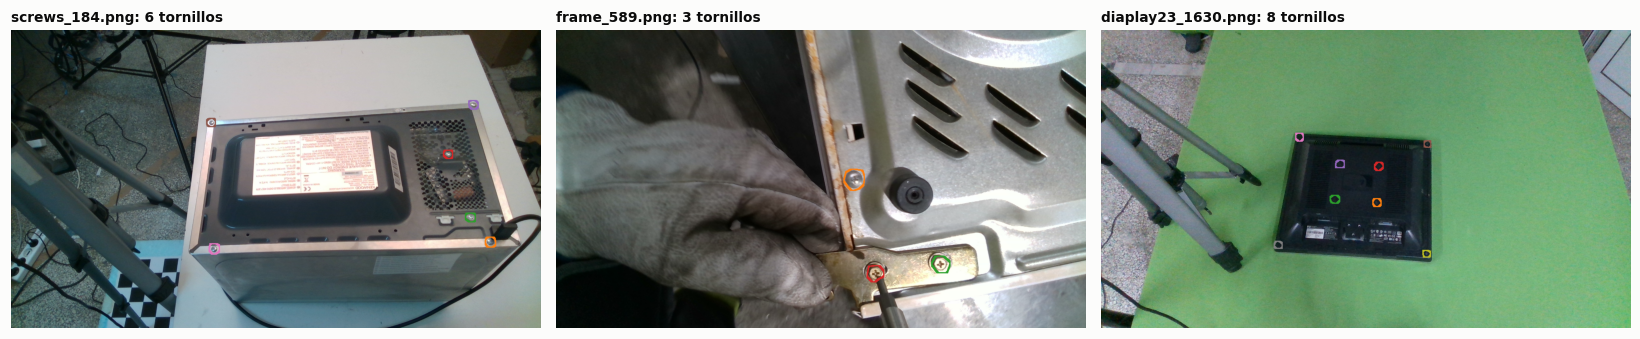

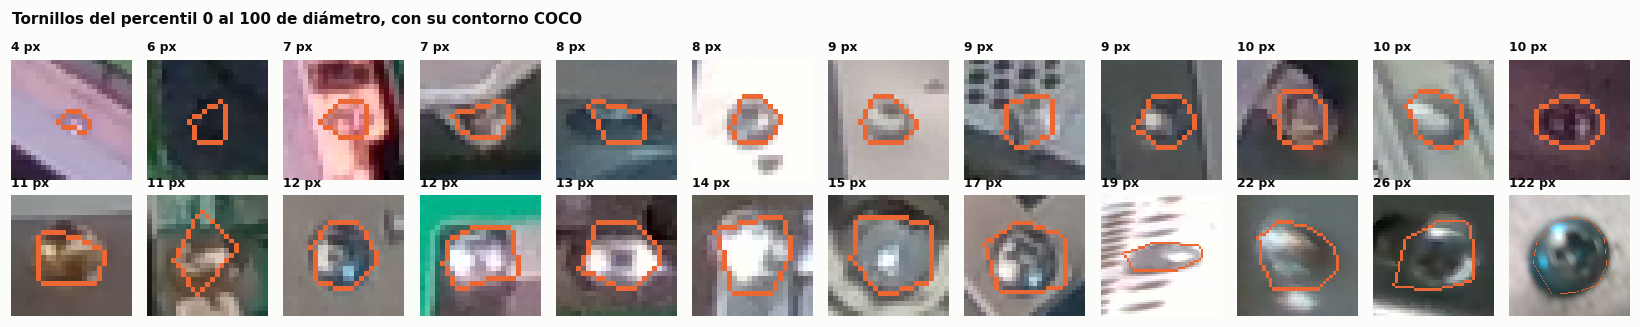

In [5]:
por_img = N._por_archivo(coco)
rutas = dict(zip(df.archivo, df.ruta_img))
fams = ['screws', 'frame', 'diaplay']
ejemplos = [par[par.familia == f].archivo.sample(1, random_state=SEED).iloc[0] for f in fams]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.3))
cmap = plt.get_cmap('tab20')
for a, arch in zip(ax, ejemplos):
    im = np.asarray(Image.open(rutas[arch]).convert('RGB')).copy()
    lab = N.etiqueta_coco(por_img[arch])
    anillo = ndi.grey_dilation(lab, size=13)
    borde = (anillo > 0) & ~ndi.binary_dilation(lab > 0, iterations=3)
    col = (np.array([cmap((2 * i) % 20)[:3] for i in range(lab.max() + 1)]) * 255).astype(np.uint8)
    im[borde] = col[anillo[borde]]
    a.imshow(im); a.set_title(f'{arch}: {lab.max()} tornillos', fontsize=9); a.axis('off'); a.grid(False)
plt.tight_layout(); plt.show()

q = ins.sort_values('diametro').iloc[np.linspace(0, len(ins) - 1, 24).astype(int)]
fig, ax = plt.subplots(2, 12, figsize=(15, 3))
for a, f in zip(ax.ravel(), q.itertuples()):
    im = np.asarray(Image.open(rutas[f.archivo]).convert('RGB'))
    lado = int(max(24, 1.6 * max(f.w, f.h))); cx, cy = int(f.cx), int(f.cy)
    y0, x0 = max(cy - lado // 2, 0), max(cx - lado // 2, 0)
    rec = im[y0:y0 + lado, x0:x0 + lado]
    lab = N.etiqueta_coco([a_ for a_ in por_img[f.archivo] if a_['id'] == f.id])[y0:y0 + lado, x0:x0 + lado]
    rec = rec.copy(); rec[find_boundaries(lab, mode='outer')] = (235, 104, 52)
    a.imshow(rec, interpolation='nearest'); a.set_title(f'{f.diametro:.0f} px', fontsize=8); a.axis('off'); a.grid(False)
fig.suptitle('Tornillos del percentil 0 al 100 de diámetro, con su contorno COCO', x=.01, ha='left', fontsize=10, fontweight='bold')
plt.tight_layout(h_pad=1.2); plt.show()

Los contornos rodean las cabezas de tornillo, pero son toscos: polígonos de pocos lados que no siguen el borde circular, sobre todo en los pequeños. Por debajo de unos 8 px de diámetro, el tornillo es una mancha de pocos píxeles sin estructura interna y la frontera exacta es ambigua, lo que explica la caída de acuerdo de la figura anterior.

**Decisión de preprocesamiento.** Ninguno: no aparecen máscaras desplazadas ni instancias vacías que obliguen a filtrar imágenes.

**Impacto en la arquitectura.** Los tornillos pequeños solo se distinguen por contraste local, así que la red debe conservar la resolución nativa en las primeras capas: nada de reducciones agresivas en la entrada ni de un primer bloque con paso 4.

**Riesgos.** Queda sin medir la tasa de tornillos sin anotar, que exigiría una auditoría manual (pendiente del README). Un tornillo sin anotar cuenta como falso positivo del modelo.

## 4. La variable objetivo: número de instancias por imagen

Instancias por imagen: media 4.65, mediana 4, mínimo 1, máximo 17
Índice de dispersión (varianza / media): 2.19  (1 en un proceso de Poisson)
Asimetría 1.06 | curtosis en exceso 0.66


,imagenes,instancias,media,mediana,maximo,pct_instancias
familia,,,,,,
screws,202,1478,7.32,7.0,16,33.61
diaplay,109,622,5.71,4.0,8,14.14
eco,136,595,4.38,4.0,11,13.53
frame,158,552,3.49,2.0,17,12.55
pc,156,484,3.10,3.0,4,11.01
micro,100,407,4.07,4.0,8,9.25
tower,53,141,2.66,2.0,11,3.21
numerico,30,118,3.93,5.0,6,2.68
screen,1,1,1.00,1.0,1,0.02


Fracción de fondo con la verdad COCO: 99.919 % (razón fondo:tornillo 1,228:1)


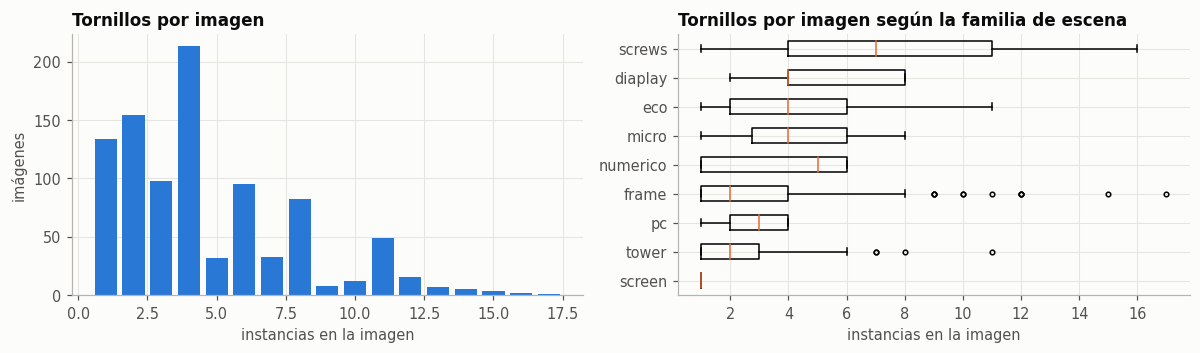

In [6]:
n_img = ins.groupby('archivo').size().reindex(par.archivo, fill_value=0)
pi = par.assign(n=n_img.values)
r = pi.n.describe()
print(f'Instancias por imagen: media {r["mean"]:.2f}, mediana {r["50%"]:.0f}, mínimo {r["min"]:.0f}, máximo {r["max"]:.0f}')
print(f'Índice de dispersión (varianza / media): {pi.n.var() / pi.n.mean():.2f}  (1 en un proceso de Poisson)')
print(f'Asimetría {stats.skew(pi.n):.2f} | curtosis en exceso {stats.kurtosis(pi.n):.2f}')
tab = pi.groupby('familia').n.agg(imagenes='size', instancias='sum', media='mean', mediana='median', maximo='max')
tab['pct_instancias'] = 100 * tab.instancias / tab.instancias.sum()
display(tab.sort_values('instancias', ascending=False).round(2))
fondo = 1 - ins.area_coco.sum() / (len(df) * E.H * E.W)
print(f'Fracción de fondo con la verdad COCO: {100 * fondo:.3f} % (razón fondo:tornillo {fondo / (1 - fondo):,.0f}:1)')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].bar(*np.unique(pi.n, return_counts=True), color=ACENTO, width=.8)
ax[0].set(title='Tornillos por imagen', xlabel='instancias en la imagen', ylabel='imágenes')
o = tab.sort_values('media').index
ax[1].boxplot([pi.n[pi.familia == f] for f in o], vert=False, labels=o, widths=.5,
              medianprops={'color': '#eb6834'}, flierprops={'markersize': 3})
ax[1].set(title='Tornillos por imagen según la familia de escena', xlabel='instancias en la imagen')
plt.tight_layout(); plt.show()

La imagen típica tiene 4 tornillos y ninguna pasa de 17. La sobredispersión es moderada y viene sobre todo de la familia `screws`, que concentra un tercio de las instancias con imágenes de hasta 16 tornillos. La familia `pc` nunca pasa de 4.

El desbalance a nivel de píxel es extremo (fondo del orden del 99,9 %), pero a nivel de instancia no hay clases que equilibrar: la dificultad es encontrar todos los objetos, no distinguir entre ellos.

**Decisión de preprocesamiento.** No se remuestrea por número de instancias. Sí se muestrean los parches de entrenamiento centrados en tornillos (por ejemplo, la mitad de los parches con al menos una instancia), porque un parche de 512×512 tomado al azar cae a menudo en fondo puro.

**Impacto en la arquitectura.** Un límite de 100 detecciones por imagen cubre de sobra el máximo de 17. La pérdida no puede ser solo entropía cruzada por píxel: con este desbalance, el óptimo trivial es predecir fondo. Se usa Dice + entropía cruzada (o focal).

**Riesgos.** Como `screws` aporta un tercio de las instancias, un F1 agregado sobre todas las instancias reflejaría sobre todo esa familia. El F1 se promedia por imagen y se reporta además por familia.

## 5. Tamaño y forma de las instancias

Diámetro equivalente (px): {'count': 4398.0, 'mean': 12.5, 'std': 7.0, 'min': 3.6, '1%': 5.0, '5%': 6.3, '25%': 8.5, '50%': 10.6, '75%': 13.9, '95%': 25.2, '99%': 37.3, 'max': 121.8}
Clases de tamaño COCO (%): {'small': 98.84, 'medium': 1.14, 'large': 0.02}
Instancias con área < 8x8 px: 30.5 %   < 16x16 px: 85.4 %
Relleno de la caja: mediana 0.76 (pi/4 = 0.79 para un círculo) | aspecto: p1 0.62, p99 2.00
Kruskal-Wallis del diámetro entre familias: H = 2030.2, p = 0.00e+00 (instancias no independientes: es descriptivo)


,size,median,p90
familia,,,
diaplay,622,7.4,10.2
pc,484,10.0,13.4
screws,1478,10.0,15.5
eco,595,10.2,12.7
numerico,118,12.1,15.6
frame,552,17.8,29.4
tower,141,18.4,27.0
micro,407,18.5,25.9
screen,1,19.5,19.5


La mitad más pequeña de los tornillos aporta el 17.4 % de los píxeles de tornillo.


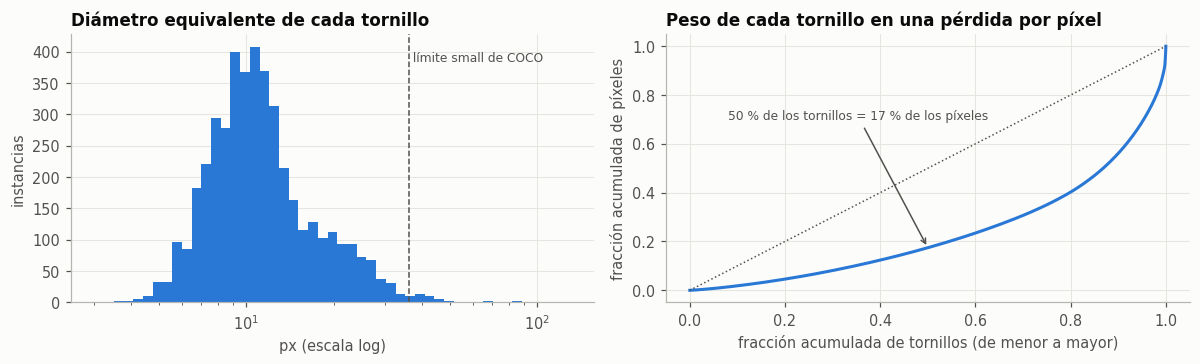

In [7]:
d = ins.diametro
print('Diámetro equivalente (px):', d.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_dict())
clases = pd.cut(ins.area_coco, [0, 32**2, 96**2, np.inf], labels=['small', 'medium', 'large'], right=False)
print('Clases de tamaño COCO (%):', (100 * clases.value_counts(normalize=True)).round(2).to_dict())
print(f'Instancias con área < 8x8 px: {100 * (ins.area_coco < 64).mean():.1f} %   < 16x16 px: {100 * (ins.area_coco < 256).mean():.1f} %')
llen = ins.area_coco / ((ins.px_x1 - ins.px_x0) * (ins.px_y1 - ins.px_y0))
asp = (ins.px_x1 - ins.px_x0) / (ins.px_y1 - ins.px_y0)
print(f'Relleno de la caja: mediana {llen.median():.2f} (pi/4 = {np.pi/4:.2f} para un círculo) | aspecto: p1 {asp.quantile(.01):.2f}, p99 {asp.quantile(.99):.2f}')
H, p = stats.kruskal(*[g.diametro for _, g in ins.groupby('familia') if len(g) > 5])
print(f'Kruskal-Wallis del diámetro entre familias: H = {H:.1f}, p = {p:.2e} (instancias no independientes: es descriptivo)')
display(ins.groupby('familia').diametro.agg(['size', 'median', lambda s: s.quantile(.9)]).rename(columns={'<lambda_0>': 'p90'}).sort_values('median').round(1))

o = np.sort(ins.area_coco.to_numpy())
cum_px = np.cumsum(o) / o.sum()
mitad = np.searchsorted(np.arange(1, len(o) + 1) / len(o), .5)
print(f'La mitad más pequeña de los tornillos aporta el {100 * cum_px[mitad]:.1f} % de los píxeles de tornillo.')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(d, bins=np.logspace(np.log10(3), np.log10(130), 50), color=ACENTO)
ax[0].set_xscale('log'); ax[0].axvline(np.sqrt(4 * 32**2 / np.pi), color=GRIS, ls='--', lw=1)
ax[0].text(np.sqrt(4 * 32**2 / np.pi), ax[0].get_ylim()[1] * .9, ' límite small de COCO', color=GRIS, fontsize=8)
ax[0].set(title='Diámetro equivalente de cada tornillo', xlabel='px (escala log)', ylabel='instancias')
ax[1].plot(np.arange(1, len(o) + 1) / len(o), cum_px, color=ACENTO, lw=2)
ax[1].plot([0, 1], [0, 1], color=GRIS, lw=1, ls=':')
ax[1].set(title='Peso de cada tornillo en una pérdida por píxel', xlabel='fracción acumulada de tornillos (de menor a mayor)',
          ylabel='fracción acumulada de píxeles')
ax[1].annotate(f'50 % de los tornillos = {100 * cum_px[mitad]:.0f} % de los píxeles', (.5, cum_px[mitad]), (.08, .7),
               arrowprops={'arrowstyle': '->', 'color': GRIS}, fontsize=8, color=GRIS)
plt.tight_layout(); plt.show()

El 98,8 % de las instancias son *small* en la convención COCO (menos de 32×32 px) y la mediana del diámetro es unos 11 px. Son objetos compactos y casi circulares: el relleno de la caja ronda $\pi/4$ y el aspecto se mantiene entre 0,6 y 2.

El tamaño depende de la familia: `diaplay` tiene los tornillos más pequeños (mediana de 7 px) y `frame`, `tower` y `micro` los mayores (unos 18 px). La consecuencia más importante está a la derecha: en una pérdida por píxel, la mitad más pequeña de los tornillos pesa muy poco, aunque en el F1 de instancia cada tornillo cuenta lo mismo.

**Decisión de preprocesamiento.** Sin reescalado hacia abajo (sección 9). Augmentations de escala limitadas a ±20 %, para no llevar los tornillos pequeños por debajo de unos 5 px.

**Impacto en la arquitectura.** La pérdida debe dar a cada instancia un peso parecido: Dice por instancia, ponderación por píxel inversa al área del tornillo o focal. En detectores tipo Mask R-CNN (Entregable 2) haría falta un nivel de paso 4 (P2) y anclas de 8 a 32 px; con paso 8, la mediana del tornillo ocupa poco más de una celda.

**Riesgos.** Con una pérdida por píxel sin ponderar, el modelo puede alcanzar buen Dice de píxel y perder la mayoría de los tornillos pequeños. Por eso el Dice de píxel no sirve como métrica primaria en este planteamiento.

## 6. Separación entre instancias: ¿basta un etiquetado de componentes conexas?

El enunciado fija como modelos base una FCN sencilla, un codificador-decodificador básico y una U-Net reducida. Estos modelos predicen una máscara por píxel, y sus instancias salen de las componentes conexas de esa máscara. Esto solo funciona si los tornillos no se tocan y si sigue funcionando cuando el modelo engorda un poco los bordes.

In [8]:
print('Solapes entre polígonos de una misma imagen: ninguno (máscara de etiquetas sin conflictos).')
print('Instancias cuya componente PNG contiene a otra instancia:', int((ins.instancias_en_componente > 1).sum()))
print('Distancia entre centros al vecino más cercano (px):', ins.dist_vecino.describe(percentiles=[.01, .05, .5]).round(1).to_dict())

radios = [0, 1, 2, 3, 5, 8]
perdidas = {r: 0 for r in radios}
imgs_fus = {r: 0 for r in radios}
for arch, anns in por_img.items():
    b = N.etiqueta_coco(anns) > 0
    for r in radios:
        m = ndi.binary_dilation(b, np.ones((3, 3)), iterations=r) if r else b
        n = measure.label(m, connectivity=2).max()
        perdidas[r] += len(anns) - n
        imgs_fus[r] += n < len(anns)
dil = pd.DataFrame({'instancias fusionadas': perdidas, '% de instancias': {r: 100 * perdidas[r] / len(ins) for r in radios},
                    'imagenes afectadas': imgs_fus})
dil.index.name = 'dilatación (px)'
display(dil.round(2))
print('Área mínima de un tornillo:', ins.area_coco.min(), 'px | percentil 1:', ins.area_coco.quantile(.01), 'px')

Solapes entre polígonos de una misma imagen: ninguno (máscara de etiquetas sin conflictos).
Instancias cuya componente PNG contiene a otra instancia: 0
Distancia entre centros al vecino más cercano (px): {'count': 4264.0, 'mean': 138.1, 'std': 105.6, 'min': 14.1, '1%': 37.4, '5%': 47.3, '50%': 103.0, 'max': 1017.6}


,instancias fusionadas,% de instancias,imagenes afectadas
dilatación (px),,,
0,0,0.00,0
1,0,0.00,0
2,1,0.02,1
3,1,0.02,1
5,4,0.09,4
8,11,0.25,10


Área mínima de un tornillo: 10 px | percentil 1: 20.0 px


Ningún par de tornillos se toca ni se solapa, y cada instancia COCO corresponde a una sola componente del PNG. Con la verdad de referencia, las componentes conexas recuperan exactamente las instancias.

La tabla simula un modelo que engorda todas las máscaras unos píxeles. Con 3 px de dilatación se fusiona un solo par de tornillos, y con 8 px solo 11 de 4.398 (0,25 %). El etiquetado por componentes es robusto a errores de borde mucho mayores que los esperables.

**Decisión de preprocesamiento.** Postproceso común a los tres modelos base: binarizar la probabilidad (umbral elegido en validación), eliminar componentes de menos de 5 px (el tornillo más pequeño tiene 10 px) y etiquetar componentes conexas con 8-vecindad. Está implementado en `N.etiqueta_mascara(mascara, area_min=5)`.

**Impacto en la arquitectura.** Los modelos base del enunciado (FCN, codificador-decodificador, U-Net reducida) son válidos para instancias sin cambios en la arquitectura. Modelos con cabeza de instancias (Mask R-CNN, YOLO-seg) quedan para el benchmark del Entregable 2.

**Riesgos.** El riesgo de fusión es bajo. El riesgo real del postproceso es el contrario: una predicción fragmentada en varias manchas genera falsos positivos. El área mínima y el umbral se ajustan en validación; si la fragmentación aparece en el piloto, se añade un cierre morfológico igual para los tres modelos.

## 7. Posición de las instancias en la imagen

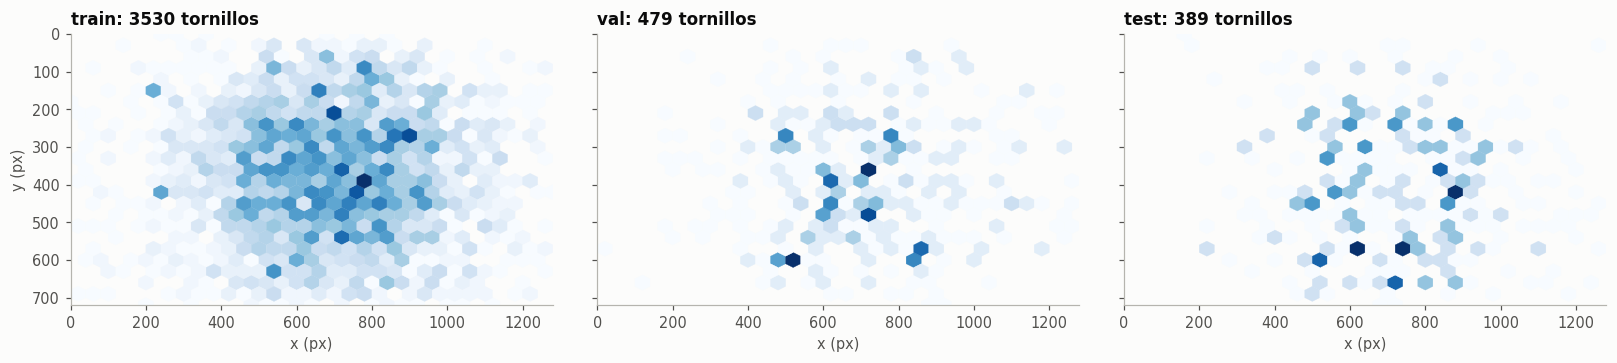

Instancias que tocan el borde de la imagen: 0
train: centro medio (691, 371) px, desviación (222, 163)
val: centro medio (705, 391) px, desviación (222, 160)
test: centro medio (732, 404) px, desviación (220, 169)


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for a, k in zip(ax, SPLITS):
    s = ins[ins.split == k]
    a.hexbin(s.cx, s.cy, gridsize=(32, 12), extent=(0, E.W, 0, E.H), cmap='Blues', mincnt=1, linewidths=.2)
    a.set(xlim=(0, E.W), ylim=(E.H, 0), title=f'{k}: {len(s)} tornillos', xlabel='x (px)'); a.set_aspect('equal'); a.grid(False)
ax[0].set_ylabel('y (px)')
plt.tight_layout(); plt.show()
borde = (ins.px_x0 <= 1) | (ins.px_y0 <= 1) | (ins.px_x1 >= E.W - 1) | (ins.px_y1 >= E.H - 1)
print('Instancias que tocan el borde de la imagen:', int(borde.sum()))
for k in SPLITS:
    s = ins[ins.split == k]
    print(f'{k}: centro medio ({s.cx.mean():.0f}, {s.cy.mean():.0f}) px, desviación ({s.cx.std():.0f}, {s.cy.std():.0f})')

Los tornillos ocupan casi toda la imagen, con más densidad en la franja central, y ninguno toca el borde. La posición viene de cómo se colocó el aparato frente a la cámara en cada escena, así que las diferencias entre particiones reflejan escenas distintas, no un sesgo de anotación.

**Decisión de preprocesamiento.** Volteos horizontales y verticales y rotaciones de 90° son admisibles: un tornillo no tiene orientación preferente y las escenas cambian de encuadre. No se necesita *padding* especial en los bordes.

**Impacto en la arquitectura.** No hace falta codificar la posición: las arquitecturas convolucionales invariantes a la traslación son adecuadas.

**Riesgos.** Si el modelo aprende la posición típica de los tornillos de cada escena, test (con escenas nuevas) lo penalizará. Esto es deseable: mide la generalización a escenas no vistas.

## 8. Sensibilidad de la IoU al desplazamiento: elección del umbral

Para objetos de 10 px, un error de un píxel cambia mucho la IoU. Se mide la IoU de cada tornillo consigo mismo desplazado 1, 2 y 3 px.

IoU mediana de un tornillo consigo mismo desplazado:


,1 px,2 px,3 px
diámetro (px),,,
"(0, 6]",0.647,0.400,0.227
"(6, 8]",0.719,0.508,0.344
"(8, 10]",0.765,0.581,0.432
"(10, 13]",0.807,0.648,0.515
"(13, 20]",0.853,0.726,0.616
"(20, 200]",0.903,0.816,0.736


Fracción de tornillos que seguirían siendo acierto tras desplazarse:


,1 px,2 px,3 px
IoU >= 0.5,99.6,88.1,49.0
IoU >= 0.75,76.6,16.2,4.5


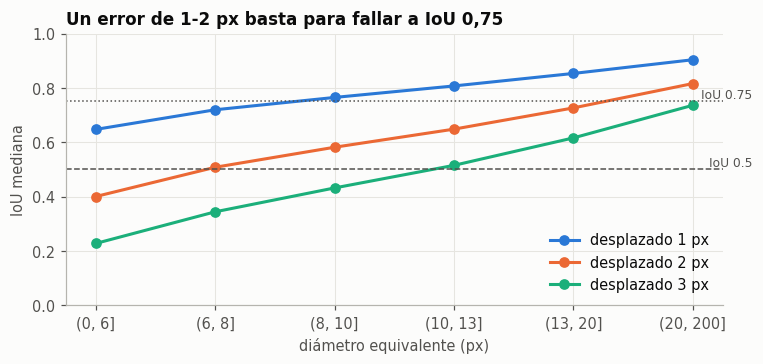

In [10]:
rango = pd.cut(ins.diametro, [0, 6, 8, 10, 13, 20, 200])
sens = ins.groupby(rango, observed=True)[['iou_auto1', 'iou_auto2', 'iou_auto3']].median()
sens.columns = ['1 px', '2 px', '3 px']; sens.index.name = 'diámetro (px)'
print('IoU mediana de un tornillo consigo mismo desplazado:'); display(sens.round(3))
tabla = pd.DataFrame({f'{s} px': {f'IoU >= {u}': (ins[f'iou_auto{s}'] >= u).mean() for u in N.UMBRALES} for s in (1, 2, 3)})
print('Fracción de tornillos que seguirían siendo acierto tras desplazarse:'); display((100 * tabla).round(1))

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(sens))
for j, (c, col) in enumerate(zip(sens.columns, ['#2a78d6', '#eb6834', '#1baf7a'])):
    ax.plot(x, sens[c], marker='o', lw=2, color=col, label=f'desplazado {c}')
for u, ls in zip(N.UMBRALES, ['--', ':']):
    ax.axhline(u, color=GRIS, ls=ls, lw=1); ax.text(len(sens) - .5, u + .01, f'IoU {u}', color=GRIS, fontsize=8, ha='right')
ax.set_xticks(x); ax.set_xticklabels([str(i) for i in sens.index])
ax.set(title='Un error de 1-2 px basta para fallar a IoU 0,75', xlabel='diámetro equivalente (px)', ylabel='IoU mediana', ylim=(0, 1))
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

A IoU 0,75, un desplazamiento de 2 px ya hace fallar a la mayoría de los tornillos. A IoU 0,5, el acierto aguanta 1 px en casi todos y 2 px en la mayoría. Junto con el techo de acuerdo de la sección 3 (F1 0,9995 a 0,5 frente a 0,91 a 0,75), esto fija el umbral.

**Decisión de preprocesamiento.** Ninguna sobre las imágenes. Las máscaras de verdad no se suavizan ni se dilatan.

**Impacto en la arquitectura.** Métrica primaria: F1 de instancia por imagen con emparejamiento húngaro e IoU ≥ 0,5 (`N.metricas_instancia`). Secundarias: SQ y PQ al mismo umbral, AP50 de máscara, error absoluto en el conteo, y Dice e IoU de píxel por imagen (las que pide el enunciado). AP 0,5:0,95 y F1 a 0,75 se reportan como informativas.

**Riesgos.** AP 0,5:0,95, el estándar de COCO, está dominada aquí por errores de 1-2 px y por el ruido de anotación. Comparar con trabajos que la usan requiere reportarla, pero no debe decidir el ranking.

## 9. Resolución de entrada y teselado

In [11]:
for esc in (1, .75, .5, .4):
    dd = ins.diametro * esc
    print(f'Escala {esc:>4}: diámetro mediano {dd.median():5.1f} px | tornillos con menos de 4 px: {100 * (dd < 4).mean():5.1f} % | menos de 6 px: {100 * (dd < 6).mean():5.1f} %')
tes = pd.DataFrame([N.cobertura_teselas(ins, t, s) for t in (256, 384, 512) for s in (0, 32, 64)])
print('\nVentanas sobre la imagen 1280x720 (la última ventana se ajusta al borde):'); display(tes.round(4))
print('Lado máximo de un tornillo:', int(max((ins.px_x1 - ins.px_x0).max(), (ins.px_y1 - ins.px_y0).max())), 'px | percentil 99:',
      int(np.percentile(np.maximum(ins.px_x1 - ins.px_x0, ins.px_y1 - ins.px_y0), 99)), 'px')

Escala    1: diámetro mediano  10.6 px | tornillos con menos de 4 px:   0.1 % | menos de 6 px:   4.1 %
Escala 0.75: diámetro mediano   8.0 px | tornillos con menos de 4 px:   1.6 % | menos de 6 px:  20.0 %
Escala  0.5: diámetro mediano   5.3 px | tornillos con menos de 4 px:  20.0 % | menos de 6 px:  63.8 %
Escala  0.4: diámetro mediano   4.3 px | tornillos con menos de 4 px:  42.8 % | menos de 6 px:  78.9 %

Ventanas sobre la imagen 1280x720 (la última ventana se ajusta al borde):


,tam,solape,ventanas,cortadas_rejilla,cubiertas_ventana
0,256,0,15,0.0923,0.9268
1,256,32,24,0.0923,0.9977
2,256,64,28,0.0923,0.9998
3,384,0,8,0.0573,0.9704
4,384,32,8,0.0573,0.9995
5,384,64,12,0.0573,1.0000
6,512,0,6,0.0452,0.9798
7,512,32,6,0.0452,1.0000
8,512,64,6,0.0452,1.0000


Lado máximo de un tornillo: 125 px | percentil 99: 41 px


Reducir la imagen a la mitad dejaría muchos tornillos por debajo de 6 px de diámetro, donde ya no se distinguen (sección 3.1). Con ventanas de 512×512 y un solape de 32 px o más, todos los tornillos caben enteros en al menos una ventana. Sin solape, el 2 % queda partido entre ventanas y se contaría como dos instancias o como ninguna.

**Decisión de preprocesamiento.** Entrenamiento con parches de 512×512 a resolución nativa. Inferencia por ventana deslizante de 512 con solape de 64 px, más que el lado de cualquier tornillo salvo los mayores. Las probabilidades se combinan en la imagen completa antes de etiquetar componentes, nunca por ventana.

**Impacto en la arquitectura.** Con entrada de 512, una U-Net reducida de 4 niveles llega a paso 16 en el cuello y conserva paso 1 y 2 en las conexiones de salto. Un tornillo de 11 px sobrevive así en el decodificador.

**Riesgos.** Etiquetar por ventana y luego unir duplicaría los tornillos del solape. Además, el solape no debe cruzar particiones: las ventanas se cortan siempre dentro de una misma imagen.

## 10. Partición: consistencia a nivel de instancia

Se usa la partición agrupada congelada del notebook 01 (`results/eda/particion.csv`, 744/93/108 imágenes, 186 grupos sin compartir). Aquí no se regenera: solo se comprueba que la variable objetivo de instancias está repartida de forma comparable.

Las instancias de una imagen, y las imágenes de un grupo, no son independientes. Por eso las pruebas permutan grupos enteros entre particiones y usan una estadística por imagen.

,imagenes,grupos,instancias,inst_por_imagen,diam_mediano,frac_pequenos,pct_instancias
split,,,,,,,
train,744,146,3530,4.745,11.284,0.174,80.264
val,93,26,479,5.151,12.715,0.161,10.891
test,108,14,389,3.602,10.846,0.302,8.845


,H,p_permutacion_grupos,p_Holm
n,17.2200,0.1910,0.5729
diam_mediano,4.7186,0.8484,1.0000
frac_pequenos,6.5782,0.7906,1.0000


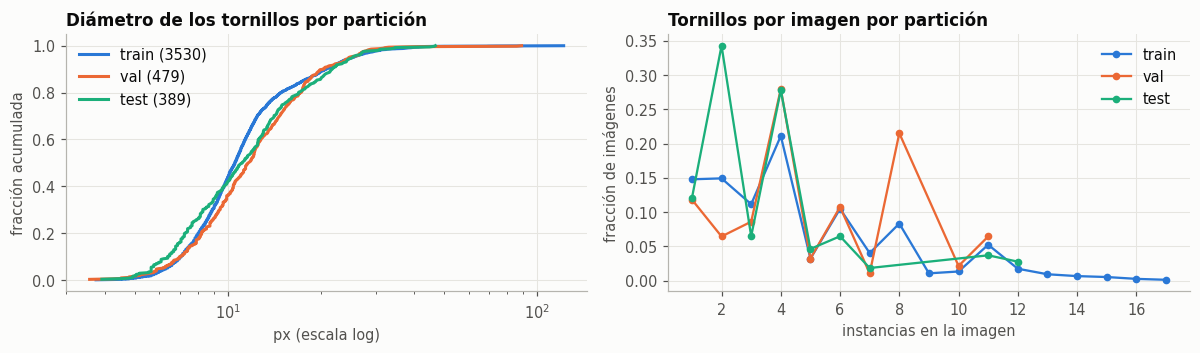

split     train   val  test
familia                    
diaplay    14.9   7.5  15.2
eco        12.1  23.4  14.4
frame      12.9   9.8  12.6
micro       8.6   9.4  14.9
numerico    3.3   0.0   0.0
pc         10.4  12.1  14.9
screen      0.0   0.0   0.0
screws     35.5  30.3  20.8
tower       2.2   7.5   7.2


In [12]:
pi['diam_mediano'] = ins.groupby('archivo').diametro.median().reindex(pi.archivo).values
pi['frac_pequenos'] = ins.assign(p=ins.diametro < 8).groupby('archivo').p.mean().reindex(pi.archivo).values
resumen = pi.groupby('split').agg(imagenes=('archivo', 'size'), grupos=('grupo', 'nunique'), instancias=('n', 'sum'),
    inst_por_imagen=('n', 'mean'), diam_mediano=('diam_mediano', 'median'), frac_pequenos=('frac_pequenos', 'mean')).loc[SPLITS]
resumen['pct_instancias'] = 100 * resumen.instancias / resumen.instancias.sum()
display(resumen.round(3))

def permuta_grupos(col, n=5000):
    """p-valor de Kruskal-Wallis entre particiones, permutando la etiqueta de partición por grupos."""
    g = pi.groupby('grupo').agg(split=('split', 'first'))
    idx = pi.grupo.map({k: i for i, k in enumerate(g.index)}).to_numpy()
    v = pi[col].to_numpy()
    def H(lab):
        s = lab[idx]
        return stats.kruskal(*[v[s == k] for k in SPLITS]).statistic
    lab0 = g.split.to_numpy()
    h0 = H(lab0)
    hs = np.array([H(rng.permutation(lab0)) for _ in range(n)])
    return h0, (1 + (hs >= h0).sum()) / (n + 1)

pr = pd.DataFrame({c: dict(zip(['H', 'p_permutacion_grupos'], permuta_grupos(c))) for c in ['n', 'diam_mediano', 'frac_pequenos']}).T
o_ = np.argsort(pr.p_permutacion_grupos.to_numpy()); m_ = len(o_)
holm = np.maximum.accumulate(np.minimum(1, (m_ - np.arange(m_)) * pr.p_permutacion_grupos.to_numpy()[o_]))
pr['p_Holm'] = np.empty(m_); pr.iloc[o_, pr.columns.get_loc('p_Holm')] = holm
display(pr.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for k in SPLITS:
    s = np.sort(ins[ins.split == k].diametro)
    ax[0].plot(s, np.arange(1, len(s) + 1) / len(s), color=COLOR[k], lw=2, label=f'{k} ({len(s)})')
    c = pi[pi.split == k].n.value_counts(normalize=True).sort_index()
    ax[1].plot(c.index, c.values, marker='o', ms=4, color=COLOR[k], lw=1.5, label=k)
ax[0].set_xscale('log'); ax[0].set(title='Diámetro de los tornillos por partición', xlabel='px (escala log)', ylabel='fracción acumulada')
ax[1].set(title='Tornillos por imagen por partición', xlabel='instancias en la imagen', ylabel='fracción de imágenes')
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()
print(pd.crosstab(ins.familia, ins.split, normalize='columns').loc[:, SPLITS].mul(100).round(1))

Test tiene menos tornillos por imagen (3,6 frente a 4,7 en train) y más tornillos pequeños, porque `screws` pesa menos en test (21 % de las instancias frente a 36 %). La permutación por grupos no distingue estas diferencias de las que produciría repartir los mismos grupos al azar (p = 0,19 para el conteo, 0,85 y 0,79 para el tamaño; tras Holm, p ≥ 0,57). Con 14 grupos en test, cualquier reparto deja diferencias visibles: no es un defecto que se pueda corregir sin romper la agrupación.

**Decisión de preprocesamiento.** La partición congelada se mantiene. No se reequilibra por número de instancias, porque eso exigiría mover imágenes de un mismo grupo entre particiones y reintroducir la fuga del split oficial.

**Impacto en la arquitectura.** Ninguno directo. El umbral de binarización y el área mínima del postproceso se ajustan en validación, nunca en test.

**Riesgos.** Las diferencias de composición entre particiones (familias y número de tornillos) hacen que el F1 de test dependa de pocos grupos. El intervalo de confianza debe remuestrear grupos (bootstrap por grupos), no solo imágenes.

## 11. Referencias sin aprendizaje

Antes de los modelos base conviene fijar las dos cotas que acotan cualquier resultado:

- **Suelo:** predecir solo fondo. Su exactitud de píxel ronda el 99,9 %, pero su F1 de instancia es 0. Por eso la exactitud de píxel no puede ser métrica de decisión.
- **Techo de anotación:** usar la otra versión de la anotación (PNG) como predicción. Ningún modelo puede superar de forma creíble este acuerdo.

In [13]:
pix_acc = 1 - ins.groupby('archivo').area_coco.sum() / (E.H * E.W)
ref = pd.DataFrame({
    'solo fondo': {'F1 instancia (IoU 0,5)': 0.0, 'PQ (IoU 0,5)': 0.0, 'exactitud de píxel': pix_acc.mean()},
    'anotación PNG': {'F1 instancia (IoU 0,5)': acu['f1_0.5'].mean(), 'PQ (IoU 0,5)': acu['pq_0.5'].mean(), 'exactitud de píxel': np.nan}})
display(ref.round(4))

,solo fondo,anotación PNG
"F1 instancia (IoU 0,5)",0.0000,0.9995
"PQ (IoU 0,5)",0.0000,0.8419
exactitud de píxel,0.9992,NaN


El F1 de instancia separa con claridad el modelo trivial (0) del techo (≈1), mientras que la exactitud de píxel los deja casi iguales. La PQ tiene un techo de 0,84 porque incluye la calidad del contorno, limitada por el ruido de anotación de la sección 3.

**Decisión de preprocesamiento.** Ninguna.

**Impacto en la arquitectura.** El margen útil para comparar modelos está en el F1 de instancia, entre 0 y casi 1. La PQ se interpreta respecto a su techo de 0,84, no respecto a 1.

**Riesgos.** Reportar la exactitud de píxel como resultado principal haría parecer bueno cualquier modelo. Se reporta solo porque el enunciado la lista.

## 12. Implicaciones para los tres modelos base

Este notebook no implementa modelos. Lo que sigue resume las restricciones que el EDA impone a quien los implemente:

| Aspecto | Decisión derivada del EDA | Sección |
|---|---|---|
| Verdad de referencia | Polígonos COCO rasterizados por centros de píxel (`N.etiqueta_coco`) | 3 |
| Familias de modelos base | FCN sencilla, codificador-decodificador básico y U-Net reducida, con salida binaria y postproceso de componentes conexas; la selección final sale de la revisión de literatura | 6 |
| Postproceso | Umbral ajustado en validación, eliminar componentes de menos de 5 px y etiquetar con 8-vecindad (`N.etiqueta_mascara`) | 6 |
| Entrada | Parches de 512×512 a resolución nativa; la mitad de los parches centrados en tornillos | 4, 9 |
| Inferencia | Ventana deslizante de 512 con solape de 64 px; etiquetado sobre la imagen completa | 9 |
| Pérdida | Dice + entropía cruzada o focal, con peso por instancia | 4, 5 |
| Augmentations | Volteos, rotaciones de 90°, escala ±20 % y fotométricas; las mismas sobre imagen y máscara | 5, 7 |
| Normalización | `results/eda/normalizacion_train.json` (calculada solo con train en el 01) | 01 |
| Métrica primaria | F1 de instancia por imagen, IoU ≥ 0,5 (`N.metricas_instancia`) | 8 |
| Inferencia estadística | Wilcoxon o t pareado sobre el F1 por imagen; IC por bootstrap de grupos | 10 |

## 13. Declaración a priori y veredicto

In [14]:
decl = {
    'fecha': '2026-11-07',
    'sustituye_a': 'declaracion_a_priori.json (orientación semántica) en métrica primaria y verdad de referencia; partición y unidad de independencia se heredan sin cambios',
    'tipo_problema': '8. Segmentación de imágenes (variante de instancias)',
    'verdad_referencia': 'Polígonos COCO rasterizados por centros de píxel (wdsd_e1.instancias.etiqueta_coco); el PNG no se usa para evaluar',
    'metrica_primaria': {'nombre': 'F1 de instancia por imagen', 'emparejamiento': 'húngaro por IoU de máscara', 'umbral_iou': 0.5,
                         'agregacion': 'media sobre imágenes', 'implementacion': 'wdsd_e1.instancias.metricas_instancia'},
    'metricas_secundarias': ['SQ y PQ a IoU 0,5', 'AP50 de máscara', 'error absoluto en el número de tornillos por imagen',
                             'Dice e IoU de píxel por imagen', 'exactitud de píxel y mIoU (solo porque el enunciado las lista)',
                             'F1 por familia de escena'],
    'metricas_informativas': ['AP 0,5:0,95 de máscara', 'F1 a IoU 0,75'],
    'delta': 0.03, 'delta_estado': 'provisional hasta el estudio piloto',
    'alpha': 0.05,
    'unidad_independencia': 'grupo de escena (columna grupo de particion.csv)',
    'particion': {'archivo': 'results/eda/particion.csv', 'tamanos': dec01['particion']['tamanos'],
                  'sha256': dec01['particion']['sha256'], 'instancias': resumen.instancias.astype(int).to_dict()},
    'postproceso': {'binarizacion': 'umbral elegido en validación', 'area_minima_px': 5, 'conectividad': 8},
    'inferencia': {'ventana': 512, 'solape': 64},
    'techo_anotacion': {'f1_iou_0.5': round(float(acu['f1_0.5'].mean()), 4), 'f1_iou_0.75': round(float(acu['f1_0.75'].mean()), 4),
                        'pq_iou_0.5': round(float(acu['pq_0.5'].mean()), 4)},
    'sha256_dataset': dec01['sha256_dataset'],
}
(E.RESULTS / 'declaracion_a_priori_instancias.json').write_text(json.dumps(decl, indent=1, ensure_ascii=False), encoding='utf8')
print(json.dumps(decl, indent=1, ensure_ascii=False))

{
 "fecha": "2026-11-07",
 "sustituye_a": "declaracion_a_priori.json (orientación semántica) en métrica primaria y verdad de referencia; partición y unidad de independencia se heredan sin cambios",
 "tipo_problema": "8. Segmentación de imágenes (variante de instancias)",
 "verdad_referencia": "Polígonos COCO rasterizados por centros de píxel (wdsd_e1.instancias.etiqueta_coco); el PNG no se usa para evaluar",
 "metrica_primaria": {
  "nombre": "F1 de instancia por imagen",
  "emparejamiento": "húngaro por IoU de máscara",
  "umbral_iou": 0.5,
  "agregacion": "media sobre imágenes",
  "implementacion": "wdsd_e1.instancias.metricas_instancia"
 },
 "metricas_secundarias": [
  "SQ y PQ a IoU 0,5",
  "AP50 de máscara",
  "error absoluto en el número de tornillos por imagen",
  "Dice e IoU de píxel por imagen",
  "exactitud de píxel y mIoU (solo porque el enunciado las lista)",
  "F1 por familia de escena"
 ],
 "metricas_informativas": [
  "AP 0,5:0,95 de máscara",
  "F1 a IoU 0,75"
 ],
 "del

**Margen δ = 0,03.** Con unos 4,7 tornillos por imagen, encontrar o perder un tornillo cambia el F1 de esa imagen en torno a 0,1. Un δ de 0,03 en el F1 medio equivale, aproximadamente, a acertar un tornillo más de cada 30. Es provisional: el piloto debe confirmarlo frente a la variabilidad entre semillas ($\delta / \hat\sigma_d$).

### Veredicto

**WDSD es válido como problema de segmentación de instancias.**

- Cada tornillo tiene su polígono, con área coherente y sin solapes.
- Los tornillos nunca se tocan, así que los tres modelos base del enunciado sirven sin cambios y producen instancias con un etiquetado de componentes conexas.
- La métrica primaria cambia a F1 de instancia por imagen con IoU ≥ 0,5. El umbral sale del propio dataset: es el único en que las dos versiones de la anotación coinciden.

**Lo que sigue igual que en el 01:** la partición agrupada, la unidad de independencia, la normalización, los parches de 512 a resolución nativa y la advertencia de que test solo tiene 14 grupos.

**Limitaciones declaradas:**

- No hay imágenes sin tornillos, así que los falsos positivos en escenas vacías no se miden.
- Los tornillos sin anotar no se han auditado.
- Las dos versiones de la anotación no son anotadores independientes, así que el techo de acuerdo es optimista.